In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
sys.path.append('..')
from shared.mlp import MLP

In [2]:
def plot_graph_and_history(x,y,z,history=None):
    # plot the 3d function approximation and the mse training history
    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.plot_surface(x, y, z, cmap='viridis')
    ax1.set_title('Function Approximation')
    ax1.set_xlabel('X-axis')
    ax1.set_ylabel('Y-axis')
    ax1.set_zlabel('Z-axis')    
    
    if history is not None:
        ax2 = fig.add_subplot(122)
        ax2.plot(history['train_mse'], label='Train MSE')
        ax2.set_title('Training MSE Rate')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('MSE Rate')     
    


(2, 10000)
(1, 10000)


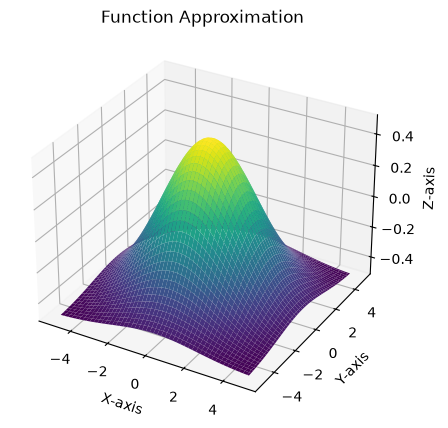

In [3]:
"""
Dataset generation for function approximation task. The function to approximate is a 2D Gaussian function defined as:
z = exp(-(x^2 + y^2) / 10) - 0.5
The input space is defined by a grid of points in the range [-5, 5] for both x and y axes, with a step size of 0.5.
"""

from numpy import cos


x = np.arange(-5, 5, 0.1)
y = np.arange(-5, 5, 0.1)

xx, yy = np.meshgrid(x, y)

z = np.exp(-(xx**2 + yy**2) / 10) - 0.5

patterns = np.vstack((
    xx.ravel(),
    yy.ravel()
))

targets = z.ravel().reshape(1, -1)

print(patterns.shape)
print(targets.shape)

plot_graph_and_history(xx, yy, z)

plt.show()

Epoch 0/1000 - Train MSE: N/A - Train Misclass: N/A
Epoch 100/1000 - Train MSE: 0.003251656250143683 - Train Misclass: 0.0354
Epoch 200/1000 - Train MSE: 0.0008068191260711869 - Train Misclass: 0.0198
Epoch 300/1000 - Train MSE: 0.0005435374342873325 - Train Misclass: 0.0173
Epoch 400/1000 - Train MSE: 0.0004258885076059489 - Train Misclass: 0.0152
Epoch 500/1000 - Train MSE: 0.00034741121518589525 - Train Misclass: 0.014
Epoch 600/1000 - Train MSE: 0.0002893459605799616 - Train Misclass: 0.0126
Epoch 700/1000 - Train MSE: 0.0002448282534406112 - Train Misclass: 0.0114
Epoch 800/1000 - Train MSE: 0.00020997392755213226 - Train Misclass: 0.0105
Epoch 900/1000 - Train MSE: 0.00018225364143829195 - Train Misclass: 0.0095


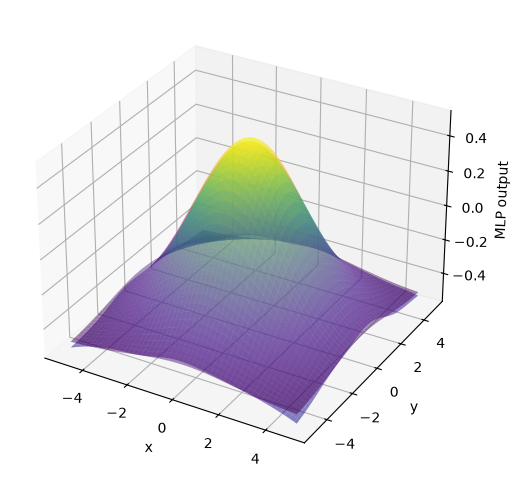

In [4]:
mlp_2 = MLP([2, 20, 1])

history = mlp_2.train(patterns, targets, eta=0.2, alpha=0.9, epochs=1000, mode="batch")

out = mlp_2.forward(patterns)
zz = out.reshape(xx.shape)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(xx, yy, zz, alpha=0.5, cmap='plasma')
ax.plot_surface(xx, yy, z, alpha=0.5, cmap='viridis')

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("MLP output")


plt.show()



In [5]:
hidden_layer_sizes = [1, 2, 3, 4, 5, 7, 10, 15, 20, 25]

#print table header with layer size, final training MSE, and epochs to convergence
print(f"{'Hidden Layer Size':<20}{'Final Training MSE':<20}{'Epochs':<20}{'Convergence Epoch':<20}")

for hidden_size in hidden_layer_sizes:
    mlp = MLP([2, hidden_size, 1])
    history = mlp.train(patterns, targets, eta=0.2, alpha=0.9, epochs=1000, mode="batch")
    out = mlp.forward(patterns)
    zz = out.reshape(xx.shape)
    converge_epoch = next(
        (epoch for epoch, mse in enumerate(history['train_mse'])
         if mse < 0.01),
        len(history['train_mse'])
    )
    
    print(f"{hidden_size:<20}{history['train_mse'][-1]:<20.6f}{len(history['train_mse']):<20}{converge_epoch if converge_epoch < len(history['train_mse']) else 'Did not converge':<20}")

    #plot_graph_and_history(xx, yy, zz, history)

Hidden Layer Size   Final Training MSE  Epochs              Convergence Epoch   
Epoch 0/1000 - Train MSE: N/A - Train Misclass: N/A
Epoch 100/1000 - Train MSE: 0.06750342399580436 - Train Misclass: 0.2185
Epoch 200/1000 - Train MSE: 0.06750277704385073 - Train Misclass: 0.2185
Epoch 300/1000 - Train MSE: 0.06750275898949767 - Train Misclass: 0.2185
Epoch 400/1000 - Train MSE: 0.06750274100990332 - Train Misclass: 0.2185
Epoch 500/1000 - Train MSE: 0.06750272308223723 - Train Misclass: 0.2185
Epoch 600/1000 - Train MSE: 0.06750270520621422 - Train Misclass: 0.2185
Epoch 700/1000 - Train MSE: 0.06750268738155141 - Train Misclass: 0.2185
Epoch 800/1000 - Train MSE: 0.06750266960796796 - Train Misclass: 0.2185
Epoch 900/1000 - Train MSE: 0.06750265188518495 - Train Misclass: 0.2185
1                   0.067503            1000                Did not converge    
Epoch 0/1000 - Train MSE: N/A - Train Misclass: N/A
Epoch 100/1000 - Train MSE: 0.05810444934282368 - Train Misclass: 0.2185
Epoc

Training Set Size   Final Training MSE  Final Validation MSE          Convergence Epoch   
(2, 2000) (2000, 2000) (2000, 2000)
Epoch 0/50 - Train MSE: N/A - Train Misclass: N/A


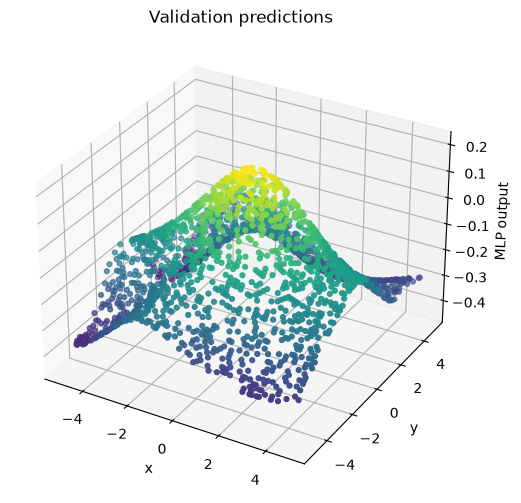

8000                0.025665            0.025962                      Did not converge    
(2, 4000) (4000, 4000) (4000, 4000)
Epoch 0/50 - Train MSE: N/A - Train Misclass: N/A


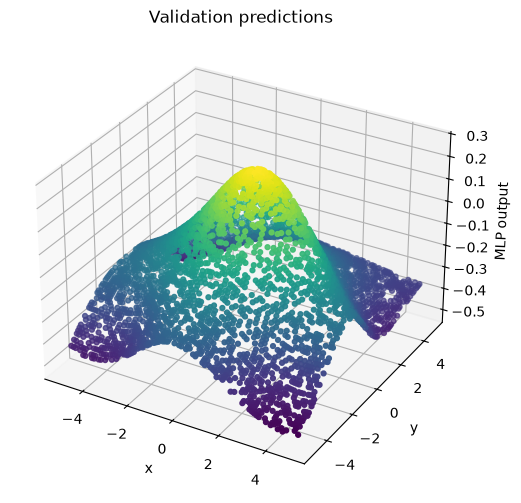

6000                0.012705            0.012290                      Did not converge    
(2, 6000) (6000, 6000) (6000, 6000)
Epoch 0/50 - Train MSE: N/A - Train Misclass: N/A


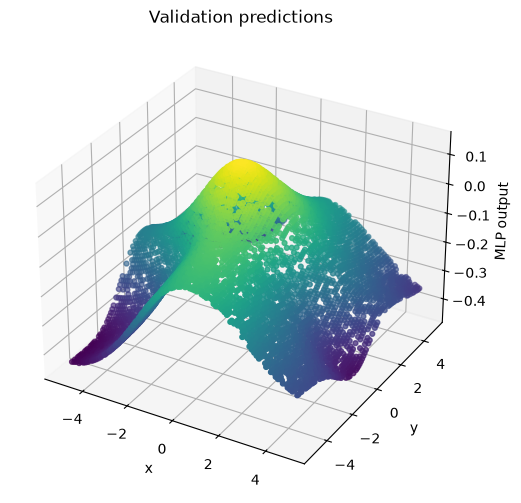

4000                0.028820            0.028880                      Did not converge    
(2, 8000) (8000, 8000) (8000, 8000)
Epoch 0/50 - Train MSE: N/A - Train Misclass: N/A


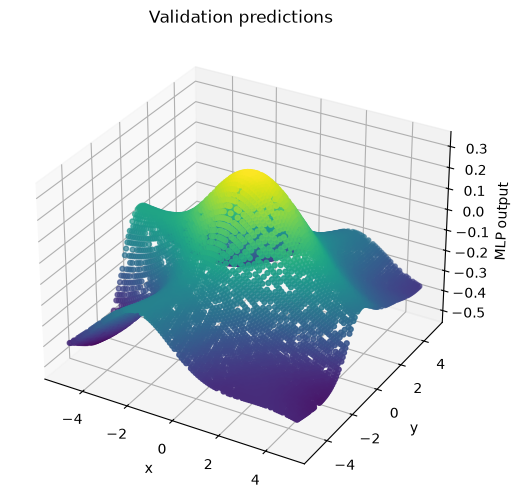

2000                0.018856            0.019777                      Did not converge    


In [6]:
"""
Tests with different training set sizes. The training set sizes are defined as a list of integers, 
where each integer represents the number of training samples to use for training the MLP. 
The MLP is trained on each training set size, and the final training MSE and the number of epochs 
to convergence are printed in a table format.
"""

training_set_sizes = [.8, .6, .4, .2]

indices = np.random.permutation(patterns.shape[1])
x = patterns[:, indices]
t = targets[:, indices]


print(f"{'Training Set Size':<20}{'Final Training MSE':<20}{'Final Validation MSE':<30}{'Convergence Epoch':<20}")
for training_size in training_set_sizes:
    train_size = int(training_size * patterns.shape[1])
    x_train = x[:, :train_size]
    t_train = t[:, :train_size]
    
    x_val = x[:, train_size:]
    t_val = t[:, train_size:]
    
    xx_val, yy_val = np.meshgrid(x_val[0, :], x_val[1, :])
    print(x_val.shape, xx_val.shape, yy_val.shape)
    
    mlp = MLP([2, 20, 1])
    history = mlp.train(x_train, t_train, eta=0.2, alpha=0.9, epochs=50, mode="batch", X_val=x_val, T_val=t_val)
    out = mlp.forward(patterns)
    zz = out.reshape(xx.shape)
    converge_epoch = next(
        (epoch for epoch, mse in enumerate(history['val_mse'])
         if mse < 0.01),
        len(history['val_mse'])
    )
    
    #plot graph using the validation set and the training history using the validation set predictions
    validation_out = mlp.forward(x_val)
    # x_val is not a regular grid; use a scatter plot instead of plot_surface
    x_val_pts = x_val[0, :]
    y_val_pts = x_val[1, :]
    z_val_pts = validation_out.ravel()

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(x_val_pts, y_val_pts, z_val_pts, c=z_val_pts, cmap='viridis', s=12)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("MLP output")
    ax.set_title("Validation predictions")
    plt.show()
    
    print(f"{train_size:<20}{history['train_mse'][-1]:<20.6f}{history['val_mse'][-1]:<30.6f}{converge_epoch if converge_epoch < len(history['train_mse']) else 'Did not converge':<20}")